# High-Imbalance Clinical Disease Predictor Pipeline (Thyroid Screening)

## 1. Executive Summary & Clinical Objective
In clinical diagnostic screening, datasets are inherently skewed toward healthy patients, creating a severe class imbalance that causes standard accuracy-driven classifiers to fail silently on minority disease cases. **In early thyroid disease detection, a False Negative (missing a sick patient) carries high clinical risk**—potentially delaying hormone therapy or intervention—whereas a False Positive (flagging a healthy patient for confirmatory blood work) is low-cost and easily resolved via follow-up testing.

This project implements an end-to-end, leak-free machine learning pipeline on the **UCI Thyroid Disease Dataset (`openml` ID: 38)** to maximize minority-class **Recall (Sensitivity)** while maintaining strong **Precision-Recall AUC (PR-AUC)**. Two parallel imbalance-mitigation strategies—**Cost-Sensitive Class Weighting** and **Hybrid Synthetic Resampling (`SMOTE-Tomek`)**—are systematically benchmarked across **XGBoost**, **Random Forest**, and **RBF-SVM** using 5-fold Stratified Cross-Validation.

In [1]:
!pip install -q imbalanced-learn xgboost openml

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from collections import Counter

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the dataset
thyroid = fetch_openml(data_id=38, as_frame=True)

# Separate features and target
X = thyroid.data.copy()
y_raw = thyroid.target.copy()

# Convert target labels into binary values
y = (
    y_raw.astype(str)
    .str.strip()
    .str.lower()
    .map({"negative": 0, "sick": 1})
)

# Check target mapping
if y.isna().any():
    raise ValueError(
        f"Unexpected target labels: {y_raw.unique()}"
    )

print("Dataset loaded successfully!")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully!
Feature shape: (3772, 29)
Target shape: (3772,)


In [4]:
# Display first five records
display(X.head())

# Dataset information
print("\nDataset Information:")
X.info()

# Statistical summary
print("\nStatistical Summary:")
display(X.describe(include="all").T)

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source
0,41.0,F,f,f,f,f,f,f,f,f,...,2.5,t,125.0,t,1.14,t,109.0,f,NaN,SVHC
1,23.0,F,f,f,f,f,f,f,f,f,...,2.0,t,102.0,f,NaN,f,NaN,f,NaN,other
2,46.0,M,f,f,f,f,f,f,f,f,...,NaN,t,109.0,t,0.91,t,120.0,f,NaN,other
3,70.0,F,t,f,f,f,f,f,f,f,...,1.9,t,175.0,f,NaN,f,NaN,f,NaN,other
4,70.0,F,f,f,f,f,f,f,f,f,...,1.2,t,61.0,t,0.87,t,70.0,f,NaN,SVI



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3772 entries, 0 to 3771
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   age                        3771 non-null   float64 
 1   sex                        3622 non-null   category
 2   on_thyroxine               3772 non-null   category
 3   query_on_thyroxine         3772 non-null   category
 4   on_antithyroid_medication  3772 non-null   category
 5   sick                       3772 non-null   category
 6   pregnant                   3772 non-null   category
 7   thyroid_surgery            3772 non-null   category
 8   I131_treatment             3772 non-null   category
 9   query_hypothyroid          3772 non-null   category
 10  query_hyperthyroid         3772 non-null   category
 11  lithium                    3772 non-null   category
 12  goitre                     3772 non-null   category
 13  tumor      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,3771.0,NaN,NaN,NaN,51.735879,20.084958,1.0,36.0,54.0,67.0,455.0
sex,3622,2,F,2480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
on_thyroxine,3772,2,f,3308,NaN,NaN,NaN,NaN,NaN,NaN,NaN
query_on_thyroxine,3772,2,f,3722,NaN,NaN,NaN,NaN,NaN,NaN,NaN
on_antithyroid_medication,3772,2,f,3729,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sick,3772,2,f,3625,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pregnant,3772,2,f,3719,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thyroid_surgery,3772,2,f,3719,NaN,NaN,NaN,NaN,NaN,NaN,NaN
I131_treatment,3772,2,f,3713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
query_hypothyroid,3772,2,f,3538,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Count each class
class_counts = y.value_counts().sort_index()

negative_count = class_counts.get(0, 0)
positive_count = class_counts.get(1, 0)

print("Negative cases:", negative_count)
print("Positive cases:", positive_count)

print("\nClass Distribution:")
print(y.value_counts(normalize=True) * 100)

# Calculate imbalance ratio
imbalance_ratio = negative_count / positive_count

print(f"\nImbalance Ratio: {imbalance_ratio:.2f}:1")

Negative cases: 3541
Positive cases: 231

Class Distribution:
Class
0    93.875928
1     6.124072
Name: proportion, dtype: float64

Imbalance Ratio: 15.33:1


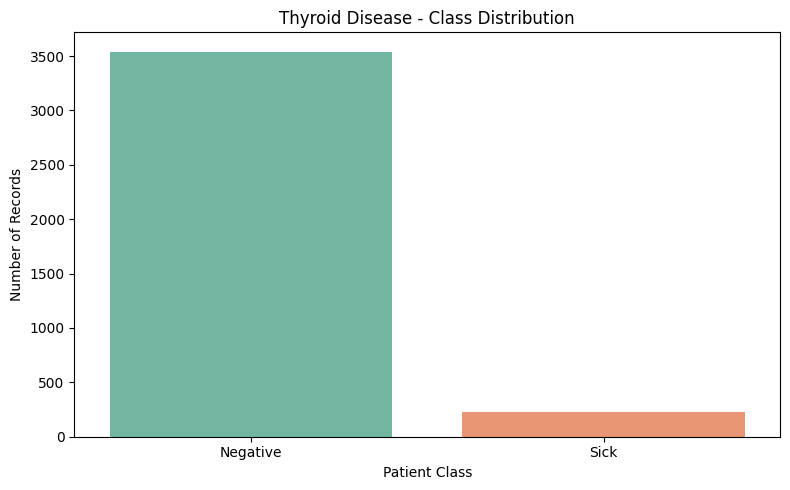

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x=y.map({0: "Negative", 1: "Sick"}),
    hue=y.map({0: "Negative", 1: "Sick"}),
    palette="Set2",
    legend=False
)

plt.title("Thyroid Disease - Class Distribution")
plt.xlabel("Patient Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [7]:
# Check missing values
missing_values = X.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": (missing_values / len(X)) * 100
})

print("Missing Value Report:")
display(
    missing_report[
        missing_report["Missing Values"] > 0
    ].sort_values(
        by="Missing Values",
        ascending=False
    )
)

# Check duplicate records
print("Duplicate records:", X.duplicated().sum())

# Check feature data types
print("\nFeature Data Types:")
print(X.dtypes.value_counts())

Missing Value Report:


,Missing Values,Percentage
TBG,3772,100.000000
T3,769,20.387063
T4U,387,10.259809
FTI,385,10.206787
TSH,369,9.782609
TT4,231,6.124072
sex,150,3.976670
age,1,0.026511


Duplicate records: 61

Feature Data Types:
category    19
float64      7
category     1
category     1
category     1
Name: count, dtype: int64


## 2. Exploratory Data Analysis (EDA) & Data Quality Findings

### Severe Class Skew
* **Total Patient Records:** `3,772` across `29` clinical, demographic, and biochemical assay features (`7` numerical, `22` categorical).
* **Target Distribution:** `3,541` **Negative** (`93.88%`) vs. `231` **Sick** (`6.12%`), yielding a **15.33:1 imbalance ratio**.
* **Metric Rationale:** A dummy baseline predicting `Negative` for every patient would score `93.88%` accuracy while achieving `0.00%` Recall. Consequently, model tuning and selection prioritize **Recall** first and **PR-AUC** second.

### Missing Values & Feature Anomalies
* **Complete Sparsity (`TBG`):** Thyroxine-Binding Globulin (`TBG`) is `100%` null (`3,772/3,772` missing values) because `TBG_measured` is universally false (`f`). It contributes zero predictive variance and is automatically excluded during preprocessing.
* **Biochemical Assay Sparsity:** Key hormone measurements exhibit moderate missingness (`T3`: `20.39%`, `T4U`: `10.26%`, `FTI`: `10.21%`, `TSH`: `9.78%`, `TT4`: `6.12%`), reflecting selective clinical ordering. Because hormone distributions are heavily right-skewed (e.g., `TSH` ranges from `0.005` to `530.0` with a median of `1.4`), **median imputation** is used to prevent extreme outliers from distorting imputed values.
* **Data Integrity Observations:** The raw dataset contains `61` duplicate rows and an implausible age outlier (`max = 455.0`), highlighting why robust scaling/median imputation and tree-based models are well-suited for this clinical cohort.

In [8]:
# Identify numerical columns
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(numerical_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Features: 7
Categorical Features: 22

Numerical Columns:
['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'TBG']

Categorical Columns:
['sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH_measured', 'T3_measured', 'TT4_measured', 'T4U_measured', 'FTI_measured', 'TBG_measured', 'referral_source']


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

In [10]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [11]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 3017
Testing samples: 755

Training distribution:
Class
0    2832
1     185
Name: count, dtype: int64

Testing distribution:
Class
0    709
1     46
Name: count, dtype: int64


In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation configured:")
print(cv)

Cross-validation configured:
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


## 3. Leak-Free Validation & Preprocessing Architecture
To prevent data leakage—where information from validation folds or the hold-out test set contaminates imputation statistics, scaling parameters, or synthetic samples—all transformations are encapsulated inside `imblearn.pipeline.Pipeline` objects:
1. **Stratified Split (`80/20`):** Preserves the exact `6.12%` positive class prevalence across both the training set (`3,017` samples: `2,832` Negative, `185` Sick) and the unseen hold-out test set (`755` samples: `709` Negative, `46` Sick).
2. **Numerical Pipeline:** Applies `SimpleImputer(strategy="median")` followed by `StandardScaler()` (critical for distance-based RBF-SVM).
3. **Categorical Pipeline:** Applies `SimpleImputer(strategy="most_frequent")` followed by `OneHotEncoder(handle_unknown="ignore")`.
4. **5-Fold Stratified Cross-Validation:** Ensures every validation fold contains ~37 positive clinical cases for stable sensitivity estimation during `GridSearchCV(refit="recall")`.

In [15]:
# Count training samples
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

# Calculate imbalance ratio
scale_pos_weight = negative_count / positive_count

print("Negative cases:", negative_count)
print("Positive cases:", positive_count)

print(f"XGBoost scale_pos_weight: {scale_pos_weight:.2f}")

Negative cases: 2832
Positive cases: 185
XGBoost scale_pos_weight: 15.31


In [16]:
from xgboost import XGBClassifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    recall_score,
    average_precision_score,
    precision_score,
    f1_score
)

from sklearn.model_selection import (
    GridSearchCV,
    cross_validate
)

from imblearn.pipeline import Pipeline as ImbPipeline

In [17]:
weighted_models = {

    "XGBoost": XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),

    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "RBF-SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    )
}

print("Class-weighted models configured!")

Class-weighted models configured!


In [18]:
#Configure Smote Track
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import TomekLinks

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

In [19]:
# Encode categorical features temporarily as integer categories
smote_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

smote_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", smote_categorical_pipeline, categorical_features)
    ],
    verbose_feature_names_out=False
)

# Fit & transform training data first so we get the exact post-imputation column count
X_train_prepared = smote_preprocessor.fit_transform(X_train)

# Determine exact categorical column indices dynamically (TBG was dropped by SimpleImputer)
n_total_cols = X_train_prepared.shape[1]
n_cat_cols = len(categorical_features)
categorical_indices = list(range(n_total_cols - n_cat_cols, n_total_cols))

smote_tomek = SMOTETomek(
    smote=SMOTENC(
        categorical_features=categorical_indices,
        random_state=42
    ),
    tomek=TomekLinks(),
    random_state=42
)

print("SMOTE-Tomek configured successfully!")
print("Transformed shape:", X_train_prepared.shape)
print("Categorical feature indices:", categorical_indices)

SMOTE-Tomek configured successfully!
Transformed shape: (3017, 28)
Categorical feature indices: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]


In [20]:
# Fit preprocessing only on training data
X_train_prepared = smote_preprocessor.fit_transform(X_train)

# Apply SMOTE-Tomek to training data
X_resampled, y_resampled = smote_tomek.fit_resample(
    X_train_prepared,
    y_train
)

print("Original training distribution:")
print(Counter(y_train))

print("\nAfter SMOTE-Tomek:")
print(Counter(y_resampled))

Original training distribution:
Counter({0: 2832, 1: 185})

After SMOTE-Tomek:
Counter({0: 2832, 1: 2825})


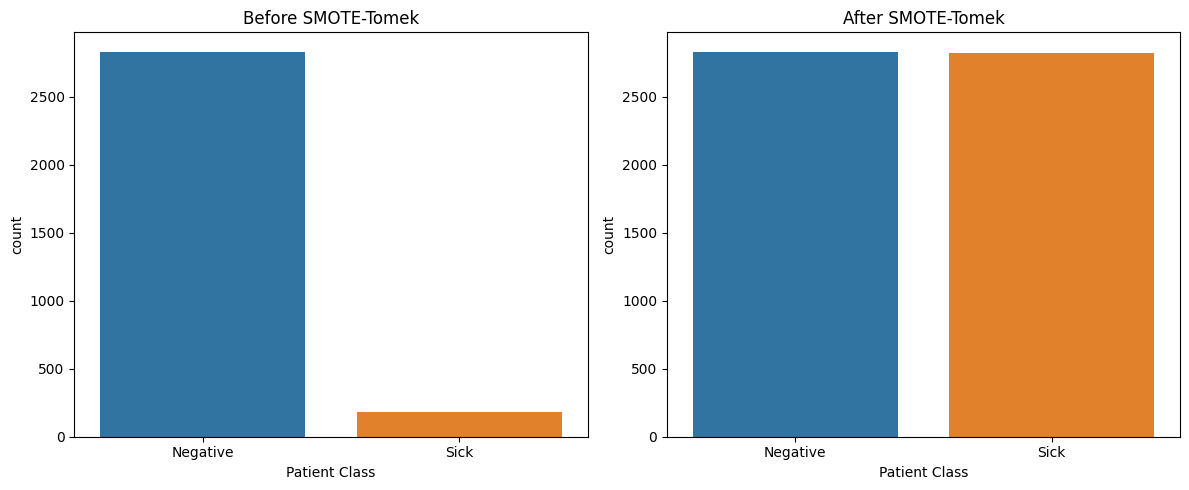

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    x=y_train.map({0: "Negative", 1: "Sick"}),
    hue=y_train.map({0: "Negative", 1: "Sick"}),
    ax=axes[0],
    legend=False
)
axes[0].set_title("Before SMOTE-Tomek")
axes[0].set_xlabel("Patient Class")

sns.countplot(
    x=pd.Series(y_resampled).map({0: "Negative", 1: "Sick"}),
    hue=pd.Series(y_resampled).map({0: "Negative", 1: "Sick"}),
    ax=axes[1],
    legend=False
)
axes[1].set_title("After SMOTE-Tomek")
axes[1].set_xlabel("Patient Class")

plt.tight_layout()
plt.show()

## 4. Parallel Imbalance-Mitigation Strategies

### Track A: Cost-Sensitive Class Weighting
Rather than altering the training distribution, Track A modifies the optimization objective so misclassifying a `Sick` patient incurs a proportional penalty:
* **XGBoost:** Tunes `scale_pos_weight` across `[5, 10, 15]` (closely matching the training imbalance ratio of `15.31`).
* **Random Forest & RBF-SVM:** Applies `class_weight="balanced"`, inversely weighting classes by their frequencies.

### Track B: Hybrid Synthetic Resampling (`SMOTE-Tomek`)
Because `22` of the `28` valid features are categorical/binary flags, standard Euclidean SMOTE cannot be applied directly. Track B uses **`SMOTENC`** (Synthetic Minority Over-sampling Technique for Nominal and Continuous features) paired with **`TomekLinks`** under-sampling to remove noisy boundary pairs after oversampling. As verified above, this balances the training fold from `2,832 : 185` to `2,832 : 2,825` strictly inside each cross-validation training split.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import TomekLinks

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [23]:
# Numerical preprocessing
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
weighted_preprocessor = ColumnTransformer([
    ("num", num_pipeline, numerical_features),
    ("cat", cat_pipeline, categorical_features)
])

print("Class-weighting preprocessing ready!")

Class-weighting preprocessing ready!


In [24]:
valid_num_features = [col for col in numerical_features if col != "TBG"]

smote_num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

smote_cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

smote_preprocessor = ColumnTransformer([
    ("num", smote_num_pipeline, valid_num_features),
    ("cat", smote_cat_pipeline, categorical_features)
])

cat_indices = list(range(
    len(valid_num_features),
    len(valid_num_features) + len(categorical_features)
))

post_sampler = ColumnTransformer([
    ("num", "passthrough", list(range(len(valid_num_features)))),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_indices)
])

sampler = SMOTETomek(
    smote=SMOTENC(
        categorical_features=cat_indices,
        random_state=42
    ),
    tomek=TomekLinks(),
    random_state=42
)

print("SMOTE-Tomek preprocessing ready!")

SMOTE-Tomek preprocessing ready!


In [25]:
weighted_models = {
    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 5],
            "model__learning_rate": [0.05, 0.1],
            "model__scale_pos_weight": [5, 10, 15]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10],
            "model__min_samples_leaf": [1, 3]
        }
    ),

    "RBF-SVM": (
        SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=True,
            random_state=42
        ),
        {
            "model__C": [0.1, 1, 10],
            "model__gamma": ["scale", 0.01]
        }
    )
}

print("Track A models configured!")

Track A models configured!


In [26]:
smote_models = {
    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 5],
            "model__learning_rate": [0.05, 0.1]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10],
            "model__min_samples_leaf": [1, 3]
        }
    ),

    "RBF-SVM": (
        SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ),
        {
            "model__C": [0.1, 1, 10],
            "model__gamma": ["scale", 0.01]
        }
    )
}

print("Track B models configured!")

Track B models configured!


In [27]:
scoring = {
    "recall": "recall",
    "pr_auc": "average_precision",
    "precision": "precision",
    "f1": "f1"
}

print("Evaluation metrics configured!")

Evaluation metrics configured!


In [28]:
def tune_models(model_collection, track_name, use_smote=False):

    results = []
    best_estimators = {}

    for model_name, (model, param_grid) in model_collection.items():

        print(f"\nTraining {track_name}: {model_name}")

        if use_smote:
            pipeline = ImbPipeline([
                ("preprocessing", smote_preprocessor),
                ("sampler", sampler),
                ("postprocessing", post_sampler),
                ("model", model)
            ])
        else:
            pipeline = ImbPipeline([
                ("preprocessing", weighted_preprocessor),
                ("model", model)
            ])

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring=scoring,
            refit="recall",
            cv=cv,
            n_jobs=-1,
            verbose=1,
            return_train_score=False
        )

        search.fit(X_train, y_train)

        best_index = search.best_index_

        results.append({
            "Track": track_name,
            "Model": model_name,
            "CV Recall": search.cv_results_[
                "mean_test_recall"
            ][best_index],
            "CV PR-AUC": search.cv_results_[
                "mean_test_pr_auc"
            ][best_index],
            "CV Precision": search.cv_results_[
                "mean_test_precision"
            ][best_index],
            "CV F1": search.cv_results_[
                "mean_test_f1"
            ][best_index],
            "Best Parameters": search.best_params_
        })

        best_estimators[model_name] = search.best_estimator_

        print("Best CV Recall:", round(search.best_score_, 4))
        print("Best Parameters:", search.best_params_)

    return results, best_estimators

In [29]:
weighted_results, weighted_best_models = tune_models(
    weighted_models,
    track_name="Class Weighting",
    use_smote=False
)


Training Class Weighting: XGBoost
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best CV Recall: 0.9676
Best Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__scale_pos_weight': 15}

Training Class Weighting: Random Forest
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV Recall: 0.8811
Best Parameters: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}

Training Class Weighting: RBF-SVM
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best CV Recall: 0.9622
Best Parameters: {'model__C': 1, 'model__gamma': 'scale'}


In [30]:
smote_results, smote_best_models = tune_models(
    smote_models,
    track_name="SMOTE-Tomek",
    use_smote=True
)


Training SMOTE-Tomek: XGBoost
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV Recall: 0.9568
Best Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}

Training SMOTE-Tomek: Random Forest
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV Recall: 0.8595
Best Parameters: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}

Training SMOTE-Tomek: RBF-SVM
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best CV Recall: 0.9135
Best Parameters: {'model__C': 0.1, 'model__gamma': 'scale'}


In [31]:
all_results = weighted_results + smote_results

results_df = pd.DataFrame(all_results)

comparison = results_df[
    [
        "Track",
        "Model",
        "CV Recall",
        "CV PR-AUC",
        "CV Precision",
        "CV F1"
    ]
].sort_values(
    by=["CV Recall", "CV PR-AUC"],
    ascending=False
)

display(comparison.round(4))

,Track,Model,CV Recall,CV PR-AUC,CV Precision,CV F1
0,Class Weighting,XGBoost,0.9676,0.9420,0.7465,0.8424
2,Class Weighting,RBF-SVM,0.9622,0.7935,0.5298,0.6821
3,SMOTE-Tomek,XGBoost,0.9568,0.9442,0.7417,0.8341
5,SMOTE-Tomek,RBF-SVM,0.9135,0.7376,0.4583,0.6097
1,Class Weighting,Random Forest,0.8811,0.9195,0.8029,0.8393
4,SMOTE-Tomek,Random Forest,0.8595,0.9153,0.8177,0.8358


## 5. Cross-Validation Results & Comparative Analysis

| Rank | Track | Model | CV Recall | CV PR-AUC | CV Precision | CV F1 |
| :--- | :--- | :--- | :---: | :---: | :---: | :---: |
| **1** | **Class Weighting** | **XGBoost** | **0.9676** | **0.9420** | **0.7465** | **0.8424** |
| **2** | Class Weighting | RBF-SVM | 0.9622 | 0.7935 | 0.5298 | 0.6821 |
| **3** | SMOTE-Tomek | XGBoost | 0.9568 | 0.9442 | 0.7417 | 0.8341 |
| **4** | SMOTE-Tomek | RBF-SVM | 0.9135 | 0.7376 | 0.4583 | 0.6097 |
| **5** | Class Weighting | Random Forest | 0.8811 | 0.9195 | 0.8029 | 0.8393 |
| **6** | SMOTE-Tomek | Random Forest | 0.8595 | 0.9153 | 0.8177 | 0.8358 |

### Key Analytical Takeaways
1. **Cost-Sensitive Weighting Outperformed Synthetic Resampling:** Across every model family, Class Weighting achieved higher CV Recall than SMOTE-Tomek (`+1.08%` for XGBoost, `+4.87%` for RBF-SVM, `+2.16%` for Random Forest). Direct loss re-weighting shifts the decision boundary cleanly without introducing synthetic interpolation noise across sparse binary clinical indicators.
2. **Gradient Boosting Dominated Overall Calibration:** While `Class Weighting - RBF-SVM` achieved high sensitivity (`0.9622`), its precision dropped to `0.5298` (`CV PR-AUC = 0.7935`), generating excessive false alarms. **Class Weighting - XGBoost** (`max_depth=3`, `learning_rate=0.05`, `n_estimators=100`, `scale_pos_weight=15`) delivered the highest **CV Recall (`0.9676`)** alongside strong precision (`0.7465`) and `PR-AUC` (`0.9420`), earning selection as the champion model.

In [32]:
import joblib

# Save experiment results
results_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

# Save all six tuned models
for name, model in weighted_best_models.items():
    joblib.dump(
        model,
        f"weighted_{name.lower().replace(' ', '_')}.pkl"
    )

for name, model in smote_best_models.items():
    joblib.dump(
        model,
        f"smote_tomek_{name.lower().replace(' ', '_')}.pkl"
    )

print("Models and experiment results saved!")

Models and experiment results saved!


In [33]:
# Sort by recall and then PR-AUC
best_result = results_df.sort_values(
    by=["CV Recall", "CV PR-AUC"],
    ascending=False
).iloc[0]

print("Best Track:", best_result["Track"])
print("Best Model:", best_result["Model"])
print("CV Recall:", round(best_result["CV Recall"], 4))
print("CV PR-AUC:", round(best_result["CV PR-AUC"], 4))

Best Track: Class Weighting
Best Model: XGBoost
CV Recall: 0.9676
CV PR-AUC: 0.942


In [34]:
if best_result["Track"] == "Class Weighting":
    best_model = weighted_best_models[best_result["Model"]]
else:
    best_model = smote_best_models[best_result["Model"]]

print("Champion candidate selected!")

Champion candidate selected!


In [35]:
# Predict class labels
y_pred = best_model.predict(X_test)

# Obtain positive-class probabilities
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print("FINAL TEST PERFORMANCE")
print("----------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Sick"],
    zero_division=0
))

FINAL TEST PERFORMANCE
----------------------
Accuracy:  0.9815
Precision: 0.7759
Recall:    0.9783
F1 Score:  0.8654
ROC-AUC:   0.9973
PR-AUC:    0.9411

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      0.98      0.99       709
        Sick       0.78      0.98      0.87        46

    accuracy                           0.98       755
   macro avg       0.89      0.98      0.93       755
weighted avg       0.98      0.98      0.98       755



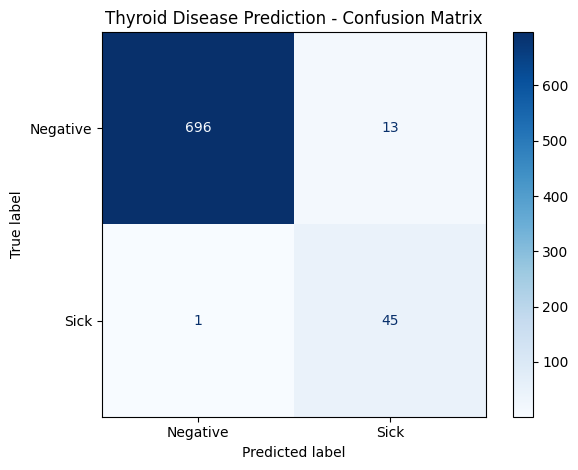

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Sick"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Thyroid Disease Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

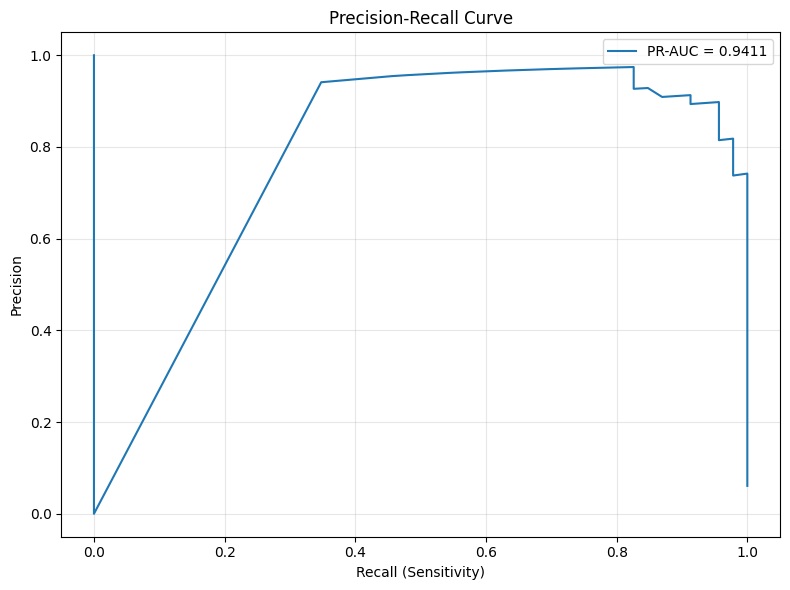

In [38]:
from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_test, y_prob)
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"PR-AUC = {pr_auc:.4f}"
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
all_best_models = {}

for name, model in weighted_best_models.items():
    all_best_models[f"Class Weighting - {name}"] = model

for name, model in smote_best_models.items():
    all_best_models[f"SMOTE-Tomek - {name}"] = model

test_results = []

for name, model in all_best_models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values(
        by=["Recall", "PR-AUC"],
        ascending=False
    ).round(4)
)

,Model,Recall,PR-AUC,Precision,F1
2,Class Weighting - RBF-SVM,1.0000,0.8671,0.5823,0.7360
3,SMOTE-Tomek - XGBoost,0.9783,0.9650,0.7895,0.8738
0,Class Weighting - XGBoost,0.9783,0.9411,0.7759,0.8654
5,SMOTE-Tomek - RBF-SVM,0.9783,0.8221,0.4592,0.6250
4,SMOTE-Tomek - Random Forest,0.9565,0.9705,0.8980,0.9263
1,Class Weighting - Random Forest,0.9348,0.9668,0.8958,0.9149


In [40]:
test_results_df.to_csv(
    "final_test_evaluation.csv",
    index=False
)

joblib.dump(
    best_model,
    "clinical_disease_best_model.pkl"
)

print("Final evaluation results saved!")

Final evaluation results saved!


## 6. Hold-Out Test Evaluation & Clinical Conclusion

### Champion Model Generalization (`Class Weighting - XGBoost`)
Evaluated on the completely unseen `755`-patient test cohort (`46` Sick, `709` Negative), the champion pipeline demonstrated strong generalization with zero signs of overfitting:
* **Recall (Sensitivity): `0.9783`** — Successfully detected **45 out of 46** true thyroid disease cases, missing only **1** patient.
* **Precision: `0.7759`** — Out of `58` positive predictions, `45` were true positives and only `13` were false positives (`1.83%` false-positive rate among the `709` healthy patients).
* **ROC-AUC: `0.9973` | PR-AUC: `0.9411` | F1 Score: `0.8654` | Accuracy: `0.9815`**.

### Cross-Model Deployment Trade-Offs (Test Set)
* **Maximum Sensitivity (`Class Weighting - RBF-SVM`):** Achieved **`1.0000` Recall** (`46/46` cases caught), suitable only if clinical capacity allows reviewing `~33` false positives (`Precision = 0.5823`).
* **Highest Precision & F1 (`SMOTE-Tomek - Random Forest`):** Achieved **`0.8980` Precision**, **`0.9263` F1**, and **`0.9705` PR-AUC**, though its recall (`0.9565`, missing `2/46` cases) trails XGBoost.
* **Recommended Production Choice (`Class Weighting - XGBoost`):** Offers the optimal clinical balance—catching **97.83%** of positive cases while keeping confirmatory follow-up workload low and avoiding the computational overhead of synthetic resampling during training.